# Regular 1

| | |
|---|---|
| Thời gian | 90 phút |
| Hình thức | Làm trực tiếp trên notebook này. Không xóa đề. |

### Rules
1. Import các thư viện đã học.
2. Mọi nhận xét viết ngắn gọn, dựa trên kết quả vừa tính — không copy insight có sẵn.
3. Chạy cell theo thứ tự từ trên xuống.
4. Biểu đồ phải có title và nhãn trục. In kết quả số ra màn hình.

### Bảng điểm tóm tắt

| Phần | Nội dung | Điểm |
|---|---|---|
| 0 | Import, load | không tính điểm |
| 1 | Inspection | 2,5 |
| 2 | Data cleaning (missing, dtype, feature) | 3,5 |
| 3 | EDA (Univariate & Multivariate) | 3,0 |
| 4 | Summary & insights | 1,0 |
| **Tổng** | | **10,0** |
| Bonus | | +2,0 |
| **Tối đa** | | **12,0** |


# Import thư viện


In [4]:
!pip install numpy pandas seaborn matplotlib scikit-learn joblib


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")

# Dataset Description

Cột gốc (file CSV):

- show_id: mã từng title
- type: Movie hoặc TV Show
- title: tên phim hoặc chương trình
- director: đạo diễn
- cast: diễn viên
- country: quốc gia sản xuất; 
- date_added: ngày thêm 
- release_year: năm phát hành gốc
- rating: xếp hạng độ tuổi
- duration: thời lượng dạng chữ. Movie là phút (90 min), TV Show là số mùa (2 Seasons)
- listed_in: thể loại; có thể nhiều tag
- description: tóm tắt nội dung


# Load data

Đọc file data.csv vào df.


In [3]:
df = pd.read_csv("data.csv")
print(df.shape)

(8807, 12)


# Phần 1 — Inspection (**2,5 đ**)

Khám phá dữ liệu gốc df trước khi clean.


### Câu 1.1 — In 10 dòng đầu (**0,1 đ**)


In [4]:
df.head(10)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",NaN,"September 24, 2021",2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,"September 24, 2021",2021,TV-14,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...


### Câu 1.2 — In thông tin dataframe (**0,1 đ**)

Số dòng, cột, dtype, non-null.


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


### Câu 1.3 — Thống kê mô tả (**0,3 đ**)

Cho biết thống kê mô tả của dataframe, thêm 5%, 15%, 30%.


In [6]:
df.describe(percentiles=[0.05, 0.15, 0.25, 0.30, 0.50, 0.75], include="all")

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s8807,Movie,Zubaan,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
5%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1997.000000,NaN,NaN,NaN,NaN
15%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2009.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN


### Câu 1.4 — Số giá trị duy nhất mỗi cột (**0,1 đ**)


In [7]:
df.nunique()

show_id         8807
type               2
title           8807
director        4528
cast            7692
country          748
date_added      1767
release_year      74
rating            17
duration         220
listed_in        514
description     8775
dtype: int64

### Câu 1.5 — Liệt kê giá trị type và rating (**0,1 đ**)


In [8]:
print("type:", df["type"].unique())
print("rating:", df["rating"].unique())

type: ['Movie' 'TV Show']
rating: ['PG-13' 'TV-MA' 'PG' 'TV-14' 'TV-PG' 'TV-Y' 'TV-Y7' 'R' 'TV-G' 'G'
 'NC-17' '74 min' '84 min' '66 min' 'NR' nan 'TV-Y7-FV' 'UR']


### Câu 1.6 — Duplicate (**0,5 đ**)

Đếm số dòng trùng.

- Nếu = 0: ghi không có trùng, giữ nguyên dữ liệu.
- Nếu > 0: quyết định xóa hay giữ. Nếu xóa thì chạy code và so sánh số dòng trước/sau. Giải thích.


In [9]:
n_dup = df.duplicated().sum()
print("Số dòng trùng:", n_dup)

if n_dup == 0:
    print("Không có dòng trùng, giữ nguyên dữ liệu.")
else:
    before = len(df)
    df = df.drop_duplicates()
    print(f"Số dòng trước: {before} - sau: {len(df)}")
    print("Đã xóa vì dòng trùng là bản ghi lặp, giữ lại sẽ làm đếm sai và lệch thống kê.")

Số dòng trùng: 0
Không có dòng trùng, giữ nguyên dữ liệu.


### Missing data (**1,3 đ** gồm câu 1.7–1.10)


### Câu 1.7 — Missing theo từng cột (**0,2 đ**)

Đếm missing theo từng cột, sắp xếp giảm dần.


In [10]:
df.isna().sum().sort_values(ascending=False)

director        2634
country          831
cast             825
date_added        10
rating             4
duration           3
show_id            0
type               0
title              0
release_year       0
listed_in          0
description        0
dtype: int64

### Câu 1.8 — Tổng missing và % trên dataset (**0,4 đ**)

Tổng missing là bao nhiêu, quy ra % trên toàn dataset là bao nhiêu (2 chữ số thập phân).


In [11]:
total_missing = df.isna().sum().sum()
pct_missing = round(total_missing / df.size * 100, 2)
print("Tổng số missing: ", total_missing)
print("Phần trăm missing: ", pct_missing, "%")

Tổng số missing:  4307
Phần trăm missing:  4.08 %


### Câu 1.9 — Bảng missing count và % (**0,3 đ**)

Tính số missing và % missing theo từng cột. Chỉ hiện cột đang thiếu. Làm tròn 2 chữ số thập phân.


In [12]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)  # pct %
missing_df = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
missing_df = missing_df[missing_df["missing_count"] > 0].sort_values("missing_count", ascending=False)
missing_df

,missing_count,missing_pct
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03


### Câu 1.10 — Barplot missing (**0,4 đ**)

Vẽ barplot % missing theo cột. Có title và nhãn trục.


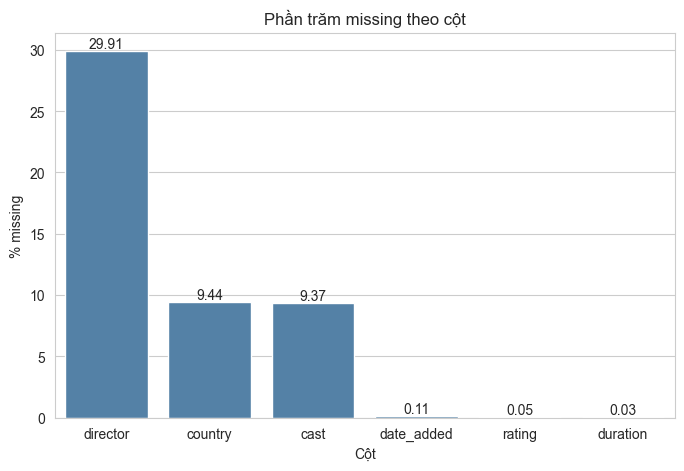

In [13]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=missing_df.index, y=missing_df["missing_pct"], color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Phần trăm missing theo cột")
plt.xlabel("Cột")
plt.ylabel("% missing")
plt.show()

# Phần 2 — Data Cleaning & Feature Engineering (**3,5 đ**)


### Câu 2.1 — tạo bản sao (**0,2 đ**)

Tạo bản sao từ df, gán vào df_clean.


In [14]:
df_clean = df.copy()

### Câu 2.2 — Cột phân loại đang thiếu (**0,3 đ**)

Kiểu phân loại (Category/Qualitative) có cột nào đang thiếu dữ liệu không?


In [15]:
cat_cols = df_clean.select_dtypes(exclude="number").columns
cat_missing = df_clean[cat_cols].isna().sum()
cat_missing = cat_missing[cat_missing > 0].sort_values(ascending=False)
print("Có, các cột phân loại đang thiếu dữ liệu:")
print(cat_missing)

Có, các cột phân loại đang thiếu dữ liệu:
director      2634
country        831
cast           825
date_added      10
rating           4
duration         3
dtype: int64


### Câu 2.3 — Xóa hay impute (**1,0 đ**)

Nếu thiếu:
- Có nên xóa không? Tại sao? Thực thi lệnh.
- Nếu không xóa thì impute dữ liệu gì, tại sao? Thực thi lệnh.


In [16]:
# Không xóa dòng: director thiếu rất nhiều, xóa sẽ mất phần lớn dữ liệu
# (các cột còn lại của dòng đó vẫn đầy đủ và dùng được).
print("Không xóa dòng, vì xóa theo các cột thiếu sẽ mất quá nhiều dòng còn dùng được.")
print("Số dòng nếu dropna():", len(df_clean.dropna()), "/", len(df_clean))

# Impute cột phân loại bằng "Unknown": giữ nguyên số dòng, không bịa thông tin cụ thể.
for col in ["director", "cast", "country", "rating", "duration"]:
    if col in df_clean.columns and df_clean[col].isna().any():
        df_clean[col] = df_clean[col].fillna("Unknown")

# date_added: không impute (không thể đoán ngày thêm), để NaT sau khi đổi sang datetime ở câu 2.4.
print(df_clean[["director", "cast", "country", "rating", "duration"]].isna().sum())

Không xóa dòng, vì xóa theo các cột thiếu sẽ mất quá nhiều dòng còn dùng được.
Số dòng nếu dropna(): 5332 / 8807
director    0
cast        0
country     0
rating      0
duration    0
dtype: int64


### Câu 2.4 — Đổi date_added sang datetime (**0,5 đ**)

Chuyển cột date_added sang datetime.
- Lưu ý: Ép về str, xóa khoảng trắng, ô không parse được dùng NaT (errors="coerce").


In [17]:
df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"].astype(str).str.strip(), errors="coerce"
)

### Câu 2.5 — Kiểm tra date_added sau khi đổi (**0,2 đ**)

In dtype và 5 dòng cột date_added.


In [18]:
print(df_clean["date_added"].dtype)
print(df_clean["date_added"].head(5))

datetime64[ns]
0   2021-09-25
1   2021-09-24
2   2021-09-24
3   2021-09-24
4   2021-09-24
Name: date_added, dtype: datetime64[ns]


### Câu 2.6 — Tạo year_added, month_added (**0,4 đ**)

Từ date_added, tạo 2 cột mới:
- year_added: năm
- month_added: tên tháng


In [19]:
df_clean["year_added"] = df_clean["date_added"].dt.year.astype("Int64")
df_clean["month_added"] = df_clean["date_added"].dt.month_name()
df_clean[["date_added", "year_added", "month_added"]].head()

,date_added,year_added,month_added
0,2021-09-25,2021,September
1,2021-09-24,2021,September
2,2021-09-24,2021,September
3,2021-09-24,2021,September
4,2021-09-24,2021,September


### Câu 2.7 — primary_country (**0,4 đ**)

Tạo cột primary_country, lấy quốc gia đầu tiên trong country.
Ví dụ: India, United States -> India


In [20]:
def first_item(text):
    parts = [p.strip() for p in str(text).split(",") if p.strip()]
    return parts[0] if parts else "Unknown"

df_clean["primary_country"] = df_clean["country"].apply(first_item)
df_clean[["country", "primary_country"]].head()

,country,primary_country
0,United States,United States
1,South Africa,South Africa
2,Unknown,Unknown
3,Unknown,Unknown
4,India,India


### Câu 2.8 — primary_genre (**0,3 đ**)

Tạo cột primary_genre, lấy thể loại đầu tiên trong listed_in.
Ví dụ: Dramas, International Movies -> Dramas


In [21]:
df_clean["primary_genre"] = df_clean["listed_in"].apply(first_item)
df_clean[["listed_in", "primary_genre"]].head()

,listed_in,primary_genre
0,Documentaries,Documentaries
1,"International TV Shows, TV Dramas, TV Mysteries",International TV Shows
2,"Crime TV Shows, International TV Shows, TV Act...",Crime TV Shows
3,"Docuseries, Reality TV",Docuseries
4,"International TV Shows, Romantic TV Shows, TV ...",International TV Shows


### Câu 2.9 — Tách duration 

Cột duration đang là chữ lẫn số (ví dụ 90 min, 2 Seasons).
Tách làm 2 cột: duration_int (số) và duration_unit (đơn vị).

Gợi ý: str.extract lấy số, str.extract lấy chữ.


In [22]:
# duration_int = phần số (90, 2, ...)
# duration_unit = min / Season / Seasons
df_clean["duration_int"] = pd.to_numeric(
    df_clean["duration"].str.extract(r"(\d+)")[0], errors="coerce"
).astype("Int64")
df_clean["duration_unit"] = df_clean["duration"].str.extract(r"([A-Za-z]+)")[0]
print(df_clean["duration_unit"].value_counts(dropna=False))

duration_unit
min        6128
Season     1793
Seasons     883
Unknown       3
Name: count, dtype: int64


### Câu 2.10 — Kiểm tra cột mới (**0,1 đ**)

In 5 dòng đầu các cột vừa tạo: type, year_added, primary_country, primary_genre, duration_int, duration_unit.


In [23]:
df_clean[["type", "year_added", "primary_country", "primary_genre", "duration_int", "duration_unit"]].head()

,type,year_added,primary_country,primary_genre,duration_int,duration_unit
0,Movie,2021,United States,Documentaries,90,min
1,TV Show,2021,South Africa,International TV Shows,2,Seasons
2,TV Show,2021,Unknown,Crime TV Shows,1,Season
3,TV Show,2021,Unknown,Docuseries,1,Season
4,TV Show,2021,India,International TV Shows,2,Seasons


# Phần 3 — EDA (**3,0 đ**)

## 3.1 Univariate analysis


### Câu 3.1 — Mô tả cột Numeric (**0,2 đ**)

Mô tả các cột Numeric sau khi clean (release_year, year_added, duration_int).


In [24]:
df_clean[["release_year", "year_added", "duration_int"]].astype(float).describe()

,release_year,year_added,duration_int
count,8807.000000,8797.000000,8804.000000
mean,2014.180198,2018.871888,69.846888
std,8.819312,1.574243,50.814828
min,1925.000000,2008.000000,1.000000
25%,2013.000000,2018.000000,2.000000
50%,2017.000000,2019.000000,88.000000
75%,2019.000000,2020.000000,106.000000
max,2021.000000,2021.000000,312.000000


### Câu 3.2 — Đếm Movie và TV Show (**0,2 đ**)

Đếm số lượng Movie và TV Show. In thêm % mỗi loại, làm tròn 1 chữ số thập phân.


In [25]:
type_counts = df_clean["type"].value_counts()
type_pct = (type_counts / len(df_clean) * 100).round(1)
print(type_counts)
print(type_pct)

type
Movie      6131
TV Show    2676
Name: count, dtype: int64
type
Movie      69.6
TV Show    30.4
Name: count, dtype: float64


### Câu 3.3 — Barplot type (**0,3 đ**)

Vẽ barplot số lượng Movie và TV Show. Có title, nhãn trục, hiện số trên cột.


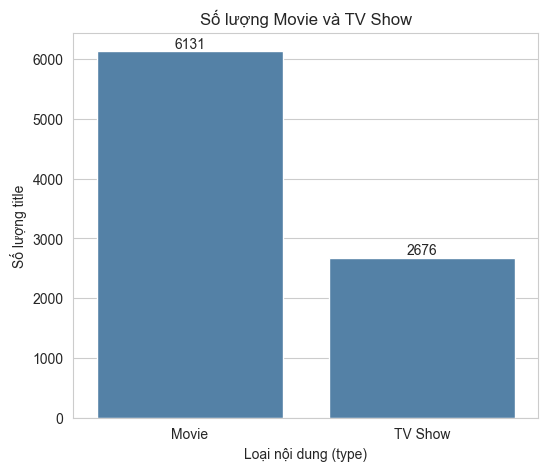

In [26]:
plt.figure(figsize=(6, 5))
ax = sns.barplot(x=type_counts.index, y=type_counts.values, color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Số lượng Movie và TV Show")
plt.xlabel("Loại nội dung (type)")
plt.ylabel("Số lượng title")
plt.show()

### Câu 3.4 — Nhận xét barplot type (**0,2 đ**)

Nhận xét barplot type (2–3 câu, dựa trên số vừa in):
- Loại nào nhiều hơn? Chiếm khoảng bao nhiêu %?
- Catalog Netflix nghiêng phim hay series?


In [27]:
top_type = type_counts.idxmax()
other_type = type_counts.idxmin()
print(f"{top_type} nhiều hơn: {type_counts.max():,} title, chiếm khoảng {type_pct.max()}%, "
      f"trong khi {other_type} có {type_counts.min():,} title ({type_pct.min()}%).")
if top_type == "Movie":
    print("Catalog Netflix nghiêng về phim (Movie) nhiều hơn series.")
else:
    print("Catalog Netflix nghiêng về series (TV Show) nhiều hơn phim.")

Movie nhiều hơn: 6,131 title, chiếm khoảng 69.6%, trong khi TV Show có 2,676 title (30.4%).
Catalog Netflix nghiêng về phim (Movie) nhiều hơn series.


### Câu 3.5 — Barplot rating (**0,3 đ**)



Content rating là gì?

Content rating = xếp hạng độ tuổi / đối tượng khán giả của phim và TV show trên Netflix.

| Rating | Ý nghĩa |
|---|---|
| TV-MA | Người lớn, nội dung mạnh |
| TV-14 | Từ khoảng 14 tuổi trở lên |
| TV-PG | Trẻ xem được nếu có hướng dẫn phụ huynh |
| PG-13 | Phim điện ảnh, dưới 13 nên có người lớn đi cùng |
| R | Restricted, dưới 17 cần người lớn |
| TV-Y / TV-G | Trẻ nhỏ / mọi lứa tuổi |




Đếm số lượng theo rating, lấy top 12. Vẽ barplot. Có title, nhãn trục.
Làm tương tự barplot type ở trên. Không copy insight có sẵn.

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
Name: count, dtype: int64


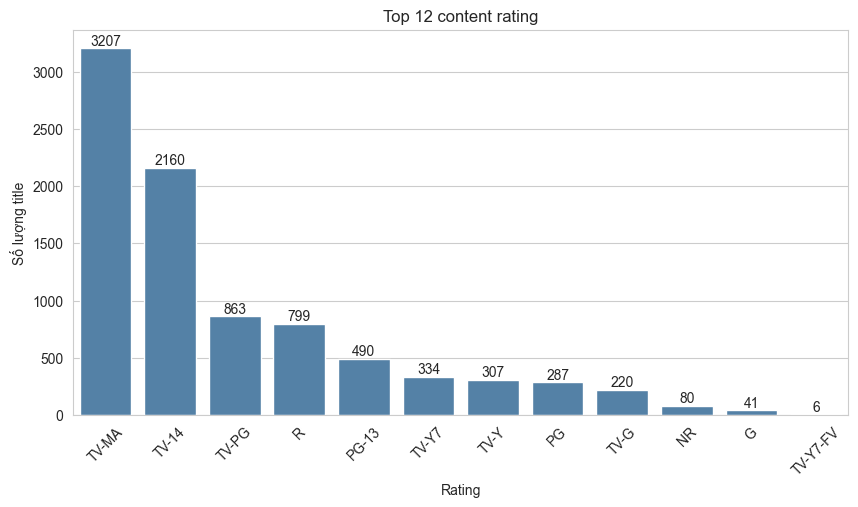

In [28]:
rating_counts = df_clean.loc[df_clean["rating"] != "Unknown", "rating"].value_counts().head(12)
print(rating_counts)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=rating_counts.index, y=rating_counts.values, color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Top 12 content rating")
plt.xlabel("Rating")
plt.ylabel("Số lượng title")
plt.xticks(rotation=45)
plt.show()

### Câu 3.6 — Nhận xét barplot rating (**0,2 đ**)

Nhận xét (dựa trên số vừa vẽ):
- Rating nào nhiều nhất? Khoảng bao nhiêu title?
- Catalog nghiêng người lớn, teen, hay trẻ em?


In [29]:
top_rating = rating_counts.idxmax()
print(f"Rating nhiều nhất là {top_rating} với khoảng {rating_counts.max():,} title.")

adult = ["TV-MA", "R", "NC-17"]
teen = ["TV-14", "PG-13"]
kids = ["TV-Y", "TV-Y7", "TV-Y7-FV", "TV-G", "G", "TV-PG", "PG"]
all_rating = df_clean["rating"].value_counts()
groups = {
    "người lớn (TV-MA, R, NC-17)": all_rating.reindex(adult).sum(),
    "teen (TV-14, PG-13)": all_rating.reindex(teen).sum(),
    "trẻ em/gia đình (TV-Y, TV-Y7, TV-G, G, TV-PG, PG)": all_rating.reindex(kids).sum(),
}
for name, n in groups.items():
    print(f"- {name}: {int(n):,} title")
print("Catalog nghiêng về nhóm", max(groups, key=groups.get))

Rating nhiều nhất là TV-MA với khoảng 3,207 title.
- người lớn (TV-MA, R, NC-17): 4,009 title
- teen (TV-14, PG-13): 2,650 title
- trẻ em/gia đình (TV-Y, TV-Y7, TV-G, G, TV-PG, PG): 2,058 title
Catalog nghiêng về nhóm người lớn (TV-MA, R, NC-17)


### Câu 3.7 — Outlier duration phim (**0,5 đ**)

Cột: duration_int, chỉ các dòng Movie (đơn vị phút). Không dùng TV Show.

Yêu cầu:
1. Boxplot duration phim.
2. Tính IQR: Q1, Q3. 
3. Đếm số điểm ngoài fence.


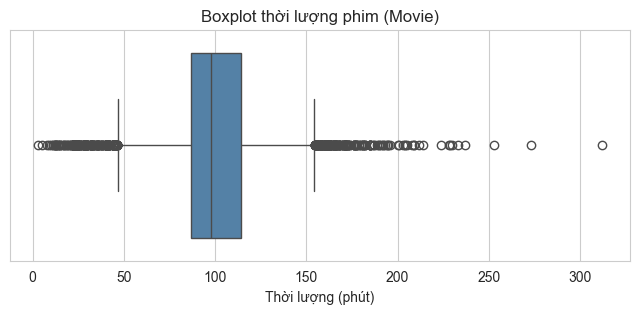

Q1 = 87.0 | Q3 = 114.0 | IQR = 27.0
Fence dưới = 46.5 | Fence trên = 154.5
Số điểm ngoài fence: 450 (7.34% số phim)


In [30]:
# lưu ý: Lọc type == Movie, lấy duration_int, bỏ NaN
movie_dur = df_clean.loc[df_clean["type"] == "Movie", "duration_int"].dropna().astype(float)

plt.figure(figsize=(8, 3))
sns.boxplot(x=movie_dur, color="steelblue")
plt.title("Boxplot thời lượng phim (Movie)")
plt.xlabel("Thời lượng (phút)")
plt.show()

Q1 = movie_dur.quantile(0.25)
Q3 = movie_dur.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
n_out = int(((movie_dur < lower) | (movie_dur > upper)).sum())
pct_out = round(n_out / len(movie_dur) * 100, 2)

print("Q1 =", Q1, "| Q3 =", Q3, "| IQR =", IQR)
print("Fence dưới =", lower, "| Fence trên =", upper)
print(f"Số điểm ngoài fence: {n_out} ({pct_out}% số phim)")

### Câu 3.8 — Quyết định outlier tiếp câu 3.7 (**0,3 đ**)

Quyết định keep / cap / remove outlier của cột này? Vì sao? 


IQR và clip khác nhau ở điểm nào? (**+0,5 đ**)


In [31]:
# Your answer here
# Keep / cap / remove: Keep
print(f"Có {n_out} phim ({pct_out}%) nằm ngoài fence [{lower:.1f}, {upper:.1f}] phút.")
print("Keep / cap / remove: Keep.")
print("Lý do: đây là phim rất ngắn hoặc rất dài có thật (không phải lỗi nhập liệu), "
      "chỉ chiếm tỉ lệ nhỏ, và xóa sẽ làm mất thông tin. Nếu sau này dùng cho mô hình nhạy outlier thì có thể cap.")

# Bonus: IQR và clip khác nhau
movie_clipped = movie_dur.clip(lower, upper)
print("Trước clip: min =", movie_dur.min(), ", max =", movie_dur.max())
print("Sau clip:   min =", movie_clipped.min(), ", max =", movie_clipped.max(), ", số dòng =", len(movie_clipped))
print("IQR chỉ là quy tắc để PHÁT HIỆN outlier (tính Q1, Q3, fence), chưa thay đổi dữ liệu. "
      "Clip là bước XỬ LÝ: kéo giá trị vượt fence về đúng giá trị fence, giữ nguyên số dòng.")

Có 450 phim (7.34%) nằm ngoài fence [46.5, 154.5] phút.
Keep / cap / remove: Keep.
Lý do: đây là phim rất ngắn hoặc rất dài có thật (không phải lỗi nhập liệu), chỉ chiếm tỉ lệ nhỏ, và xóa sẽ làm mất thông tin. Nếu sau này dùng cho mô hình nhạy outlier thì có thể cap.
Trước clip: min = 3.0 , max = 312.0
Sau clip:   min = 46.5 , max = 154.5 , số dòng = 6128
IQR chỉ là quy tắc để PHÁT HIỆN outlier (tính Q1, Q3, fence), chưa thay đổi dữ liệu. Clip là bước XỬ LÝ: kéo giá trị vượt fence về đúng giá trị fence, giữ nguyên số dòng.


## 3.2 Multivariate analysis


### Câu 3.9 — Correlation (**0,5 đ**)

Corr các cột release_year, year_added, duration_int.

Gợi ý: duration_int Movie. Nên lọc type == Movie trước khi corr.

Yêu cầu:
1. In ma trận corr.
2. Heatmap, có annot.


              release_year  year_added  duration_int
release_year      1.000000    0.039285     -0.206285
year_added        0.039285    1.000000      0.124436
duration_int     -0.206285    0.124436      1.000000


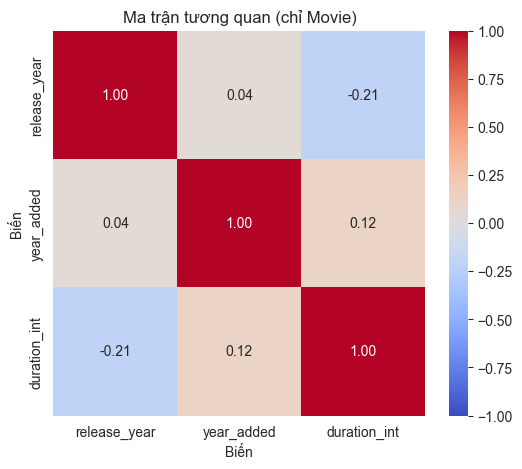

In [32]:
movies = df_clean[df_clean["type"] == "Movie"]
corr_cols = ["release_year", "year_added", "duration_int"]
corr = movies[corr_cols].astype(float).corr()
print(corr)

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Ma trận tương quan (chỉ Movie)")
plt.xlabel("Biến")
plt.ylabel("Biến")
plt.show()

### Câu 3.10 — Nhận xét corr (**0,3 đ**)

Nhận xét cặp tương quan nổi bật (dương/âm, mạnh/yếu). Ý nghĩa 1 câu.


In [33]:
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr_cols) for b in corr_cols[i + 1:]]
a, b, r = max(pairs, key=lambda t: abs(t[2]))
strength = "mạnh" if abs(r) >= 0.7 else "vừa" if abs(r) >= 0.3 else "yếu"
direction = "dương" if r > 0 else "âm"
print(f"Cặp nổi bật: {a} và {b}, corr = {r:.2f} (tương quan {direction}, {strength}).")
print(f"Ý nghĩa: khi {a} tăng thì {b} có xu hướng {'tăng' if r > 0 else 'giảm'}, "
      f"nhưng mức liên hệ {strength} và đây không phải quan hệ nhân quả.")

Cặp nổi bật: release_year và duration_int, corr = -0.21 (tương quan âm, yếu).
Ý nghĩa: khi release_year tăng thì duration_int có xu hướng giảm, nhưng mức liên hệ yếu và đây không phải quan hệ nhân quả.


# Phần 4 — Summary và insights (**1,0 đ**)

Điền vào chỗ trống. Lấy số từ output đã chạy. Không bịa số.


### Câu 4.1–4.3

**(1) Chất lượng dữ liệu — 0,3 đ**
Toàn bộ dataset thiếu khoảng ...... %. Cột thiếu nhiều nhất là ...... (khoảng ...... %).
Cột nhóm em fill bằng ...... .

**(2) Catalog — 0,4 đ**
Movie chiếm khoảng ...... %, TV Show khoảng ...... %.
Rating phổ biến nhất: ...... .

**(3) Chọn đúng 1 trong 2 — 0,3 đ**
Outlier: cột duration_int (chỉ Movie, phút) có / không có outlier rõ. Em chọn keep / cap / remove vì ......
hoặc
Tương quan: cặp ...... và ...... có corr khoảng ...... (dương/âm, mạnh/yếu). Ý nghĩa: ......


In [34]:
top_missing_col = missing_df.index[0]
top_missing_pct = missing_df.iloc[0]["missing_pct"]

print("(1) Chất lượng dữ liệu")
print(f"Toàn bộ dataset thiếu khoảng {pct_missing} %. Cột thiếu nhiều nhất là {top_missing_col} (khoảng {top_missing_pct} %).")
print("Cột nhóm em fill bằng Unknown (director, cast, country, rating); date_added giữ NaT, không fill.")

print()
print("(2) Catalog")
print(f"Movie chiếm khoảng {type_pct.get('Movie', 0)} %, TV Show khoảng {type_pct.get('TV Show', 0)} %.")
print(f"Rating phổ biến nhất: {top_rating}.")

print()
print("(3) Outlier")
has_outlier = "có" if n_out > 0 else "không có"
print(f"Outlier: cột duration_int (chỉ Movie, phút) {has_outlier} outlier rõ ({n_out} phim, {pct_out}%). "
      "Em chọn keep vì đây là giá trị thật, tỉ lệ nhỏ, xóa sẽ mất thông tin.")

(1) Chất lượng dữ liệu
Toàn bộ dataset thiếu khoảng 4.08 %. Cột thiếu nhiều nhất là director (khoảng 29.91 %).
Cột nhóm em fill bằng Unknown (director, cast, country, rating); date_added giữ NaT, không fill.

(2) Catalog
Movie chiếm khoảng 69.6 %, TV Show khoảng 30.4 %.
Rating phổ biến nhất: TV-MA.

(3) Outlier
Outlier: cột duration_int (chỉ Movie, phút) có outlier rõ (450 phim, 7.34%). Em chọn keep vì đây là giá trị thật, tỉ lệ nhỏ, xóa sẽ mất thông tin.


# Encoding 


### Câu B1 — Encoding cột type (**+0,7 đ**)

Cột type nên dùng one-hot hay label? Vì sao? Viết code thực thi.


In [35]:
# type chỉ có 2 giá trị và không có thứ tự -> one-hot (drop_first=True cho ra 1 cột 0/1).
# Không dùng label vì label gán số thứ tự (0,1,2...) có thể bị hiểu nhầm là có hơn/kém; với nhiều nhóm sẽ sai.
type_encoded = pd.get_dummies(df_clean["type"], prefix="type", drop_first=True, dtype=int)
df_encoded = pd.concat([df_clean, type_encoded], axis=1)
print("Vì type là biến phân loại danh nghĩa (không có thứ tự) nên dùng one-hot.")
df_encoded[["type"] + list(type_encoded.columns)].head()

Vì type là biến phân loại danh nghĩa (không có thứ tự) nên dùng one-hot.


,type,type_TV Show
0,Movie,0
1,TV Show,1
2,TV Show,1
3,TV Show,1
4,TV Show,1


### Câu B2 — Encoding rating / primary_genre (**+0,8 đ**)

Cột rating hoặc primary_genre nên dùng loại nào? Vì sao? Viết code thực thi.


In [36]:
# rating có thứ tự mức độ nội dung tăng dần (trẻ em -> người lớn) -> dùng ordinal/label encoding theo thứ tự.
rating_order = {
    "TV-Y": 0, "TV-Y7": 1, "TV-Y7-FV": 1, "TV-G": 2, "G": 2,
    "TV-PG": 3, "PG": 3, "TV-14": 4, "PG-13": 4,
    "R": 5, "TV-MA": 5, "NC-17": 6,
}
# NR, UR, Unknown là chưa phân loại nên không có mức -> NaN
df_encoded["rating_encoded"] = df_encoded["rating"].map(rating_order)
print("rating có thứ tự nên dùng ordinal encoding, không dùng one-hot vì mất thông tin thứ tự.")
print("primary_genre không có thứ tự và có nhiều nhóm -> nếu cần mã hóa thì dùng one-hot cho top nhóm (còn lại gộp Other).")
print(df_encoded[["rating", "rating_encoded"]].drop_duplicates().sort_values("rating_encoded"))

rating có thứ tự nên dùng ordinal encoding, không dùng one-hot vì mất thông tin thứ tự.
primary_genre không có thứ tự và có nhiều nhóm -> nếu cần mã hóa thì dùng one-hot cho top nhóm (còn lại gộp Other).
        rating  rating_encoded
23        TV-Y             0.0
34       TV-Y7             1.0
6581  TV-Y7-FV             1.0
66        TV-G             2.0
107          G             2.0
6           PG             3.0
13       TV-PG             3.0
0        PG-13             4.0
8        TV-14             4.0
1        TV-MA             5.0
46           R             5.0
5264     NC-17             6.0
5541    74 min             NaN
5794    84 min             NaN
5813    66 min             NaN
5971        NR             NaN
5989   Unknown             NaN
7058        UR             NaN
